# Análisis y preprocesamiento de datos

Este notebook organiza en diez etapas la preparación de `data_proyecto.csv` para análisis y para un futuro modelo de aprendizaje automático. Los resultados se mantienen en memoria; no se crean archivos auxiliares. El análisis conserva los registros y documenta las decisiones para que puedan revisarse antes de entrenar un modelo.

## 1. Carga

Se carga el archivo fuente, se conservan las columnas relevantes y se usa el tipo categórico para reducir el consumo de memoria en las columnas con valores repetidos. Los códigos geográficos se leen como texto porque representan identificadores, no cantidades.

In [1]:
# Importar las herramientas estándar para datos, gráficos y etapas posteriores del flujo.
from pathlib import Path
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from scipy.sparse import coo_matrix
from scipy.sparse.linalg import LinearOperator, eigsh
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from IPython.display import display

# Definir la ubicación del dataset indicada para este proyecto.
RUTA_DATASET = Path(r'C:\Users\PAULA\Documents\IntegradorG3\data\processed\dataset_proyecto_preparado.csv')

# Seleccionar las columnas útiles y excluir columnas sin nombre que vienen vacías en el CSV.
COLUMNAS_FUENTE = ['Fecha', 'provincia', 'Canton', 'Cod_Parroquia', 'Parroquia', 'Servicio', 'Subtipo']

# Definir las variables categóricas originales, incluidos los códigos geográficos.
COLUMNAS_CATEGORICAS = ['provincia', 'Canton', 'Cod_Parroquia', 'Parroquia', 'Servicio', 'Subtipo']

# Detener el proceso con un error claro si la ruta o el archivo no existen.
if not RUTA_DATASET.is_file():
    raise FileNotFoundError(f'No se encontró el dataset en: {RUTA_DATASET}')

# Cargar todos los registros como categorías y conservar textos como "nan" si fueran valores literales.
df = pd.read_csv(
    RUTA_DATASET,
    usecols=COLUMNAS_FUENTE,
    dtype={columna: 'category' for columna in COLUMNAS_FUENTE},
    keep_default_na=False,
    na_values=[''],
    on_bad_lines='error'
)

# Mostrar dimensiones, memoria ocupada y una pequeña vista para comprobar la lectura.
print(f'Registros cargados: {len(df):,}')
print(f'Columnas cargadas: {len(df.columns)}')
print(f'Memoria del DataFrame: {df.memory_usage(deep=True).sum() / 1024**3:.2f} GiB')
display(df.head())

# Presentar la distribución de filas leídas como una tabla resumida.
display(pd.DataFrame({'métrica': ['filas', 'columnas'], 'valor': [len(df), len(df.columns)]}))

Registros cargados: 17,680,253
Columnas cargadas: 7
Memoria del DataFrame: 0.20 GiB


,Fecha,provincia,Canton,Cod_Parroquia,Parroquia,Servicio,Subtipo
0,1/8/2025,NAPO,ARCHIDONA,150350.0,"ARCHIDONA, CABECERA CANTONAL",Servicio Militar,Seguridad exterior a C.P.L.
1,1/8/2025,PICHINCHA,QUITO,170155.0,CALDERÓN (CARAPUNGO),Seguridad Ciudadana,Apoyo a instituciones articuladas
2,1/8/2025,PICHINCHA,QUITO,170152.0,AMAGUAÑA,Gestión Sanitaria,Consulta médica
3,1/8/2025,PICHINCHA,QUITO,170150.0,"QUITO DISTRITO METROPOLITANO, CABECERA CANTONA...",Tránsito y Movilidad,Otros
4,1/8/2025,PICHINCHA,QUITO,170175.0,PIFO,Seguridad Ciudadana,Presencia policial


,métrica,valor
0,filas,17680253
1,columnas,7


### Hallazgos y análisis

La salida de la celda informa el número real de filas y columnas cargadas, el consumo de memoria y una vista de registros. Se seleccionan siete campos fuente y se excluyen las columnas vacías `Unnamed`; las seis variables categóricas se conservarán como identificadores o categorías. Los valores concretos deben verificarse en la tabla que aparece al ejecutar la celda.

**Conclusión.** El dataset queda cargado completo en `df`, con columnas categóricas comprimidas y códigos geográficos preservados como texto. Si la ruta no está disponible en otro equipo, debe actualizarse `RUTA_DATASET` antes de ejecutar.

## 2. Inspección

Se revisan dimensiones, tipos de datos, memoria, valores ausentes, duplicados y cardinalidad. Esta etapa permite detectar problemas estructurales antes de modificar o transformar el dataset.

,tipo,valores_unicos,faltantes,faltantes_pct,memoria_MiB
Canton,category,224.0,2144.0,0.012127,33.742917
Cod_Parroquia,category,1042.0,2148.0,0.012149,33.810154
Fecha,category,2066.0,0.0,0.000000,33.899945
Index,NaN,NaN,NaN,NaN,0.000126
Parroquia,category,980.0,2144.0,0.012127,33.825994
Servicio,category,7.0,2221.0,0.012562,16.862083
Subtipo,category,693.0,88.0,0.000498,33.803546
provincia,category,26.0,2144.0,0.012127,16.863688


Registros exactamente duplicados: 11,745,103


,frecuencia
Fecha,
1/1/2022,20326
01/01/2023,15532
31/10/2021,15473
5/12/2021,15188
25/12/2021,15114
05/09/2021,14854
1/1/2026,14736
1/1/2025,14731
22/8/2021,14706


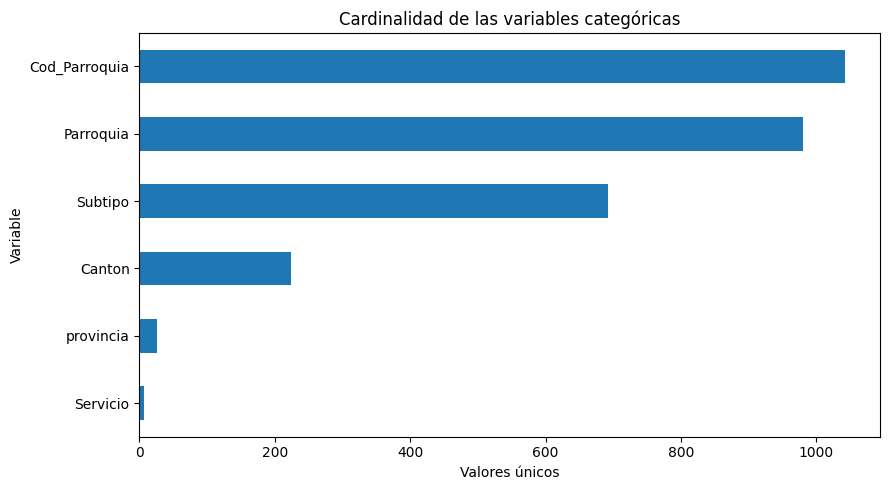

In [2]:
# Construir un resumen de tipos, cardinalidades y valores faltantes sin mostrar millones de filas.
resumen_inspeccion = pd.DataFrame({
    'tipo': df.dtypes.astype(str),
    'valores_unicos': df.nunique(dropna=True),
    'faltantes': df.isna().sum(),
    'faltantes_pct': df.isna().mean() * 100,
    'memoria_MiB': df.memory_usage(deep=True) / 1024**2
})

# Calcular duplicados exactos como diagnóstico, sin eliminar registros en esta etapa.
duplicados_exactos = int(df.duplicated().sum())

# Mostrar la tabla y las fechas originales más frecuentes para comprobar formatos.
display(resumen_inspeccion)
print(f'Registros exactamente duplicados: {duplicados_exactos:,}')
display(df['Fecha'].value_counts(dropna=False).head(10).to_frame('frecuencia'))

# Graficar la cardinalidad de los campos categóricos para distinguir identificadores de categorías.
ax = resumen_inspeccion.loc[COLUMNAS_CATEGORICAS, 'valores_unicos'].sort_values().plot.barh(figsize=(9, 5))
ax.set(title='Cardinalidad de las variables categóricas', xlabel='Valores únicos', ylabel='Variable')
plt.tight_layout()
plt.show()

### Hallazgos y análisis

La tabla muestra el tipo de cada columna, cantidad y porcentaje de faltantes, número de valores únicos y memoria utilizada. La cardinalidad de `Cod_Parroquia` debe interpretarse como identificador, no como variable numérica continua. Los duplicados se reportan para revisión, pues pueden representar incidentes repetidos legítimos; no se eliminan automáticamente.

**Conclusión.** La estructura queda documentada antes de las transformaciones. Las decisiones de corregir duplicados, categorías o formatos deberán basarse en reglas de negocio y no únicamente en una coincidencia de valores.

## 3. EDA (Análisis Exploratorio de Datos)

Se describen las distribuciones de las variables categóricas mediante frecuencias, porcentajes, moda, cardinalidad, entropía y Gini. Se analizan asociaciones con tablas de contingencia, Chi-cuadrado y V de Cramér; además, se construye una proyección MCA dispersa para evitar una matriz densa de millones de filas.

,cardinalidad,moda,porcentaje_moda,entropia_bits,gini
variable,,,,,
provincia,27,PICHINCHA,24.614767,3.606063,0.863995
Canton,225,QUITO,21.824190,5.202934,0.913676
Cod_Parroquia,1043,90150.0,17.053189,6.160118,0.936368
Parroquia,981,"GUAYAQUIL, CABECERA CANTONAL Y CAPITAL PROVINCIAL",17.052997,6.137382,0.936350
Servicio,8,Seguridad Ciudadana,69.393673,1.500013,0.490609
Subtipo,694,Patrullaje policial en el sector solicitado,24.629829,5.644299,0.924261


Frecuencias completas: provincia


,frecuencia,porcentaje
provincia,,
PICHINCHA,4351953,24.614767
GUAYAS,4259613,24.092489
AZUAY,975992,5.520238
MANABI,878137,4.966767
LOS RIOS,784872,4.439258
EL ORO,763942,4.320877
TUNGURAHUA,748836,4.235437
IMBABURA,628233,3.553303
SANTO DOMINGO DE LOS TSACHILAS,608666,3.442632


Frecuencias completas: Servicio


,frecuencia,porcentaje
Servicio,,
Seguridad Ciudadana,12268977,69.393673
Gestión Sanitaria,2073797,11.729453
Tránsito y Movilidad,1879422,10.630063
Servicios Municipales,851552,4.816402
Gestión de Siniestros,305453,1.727651
Servicio Militar,210828,1.192449
Gestión de Riesgos,88003,0.497747
NaN,2221,0.012562


Frecuencias completas: Subtipo


,frecuencia,porcentaje
Subtipo,,
Patrullaje policial en el sector solicitado,4354616,24.629829
Libadores,1332668,7.537607
Presencia policial,941924,5.327548
Resguardo a personas que traslada valores a nivel local,569908,3.223415
Escándalo en espacio público,550735,3.114972
...,...,...
Explotación y transporte ilegal de madera,2,0.000011
Déficit hídrico,1,0.000006
Explotación y transporte ilegal de fauna protegida,1,0.000006


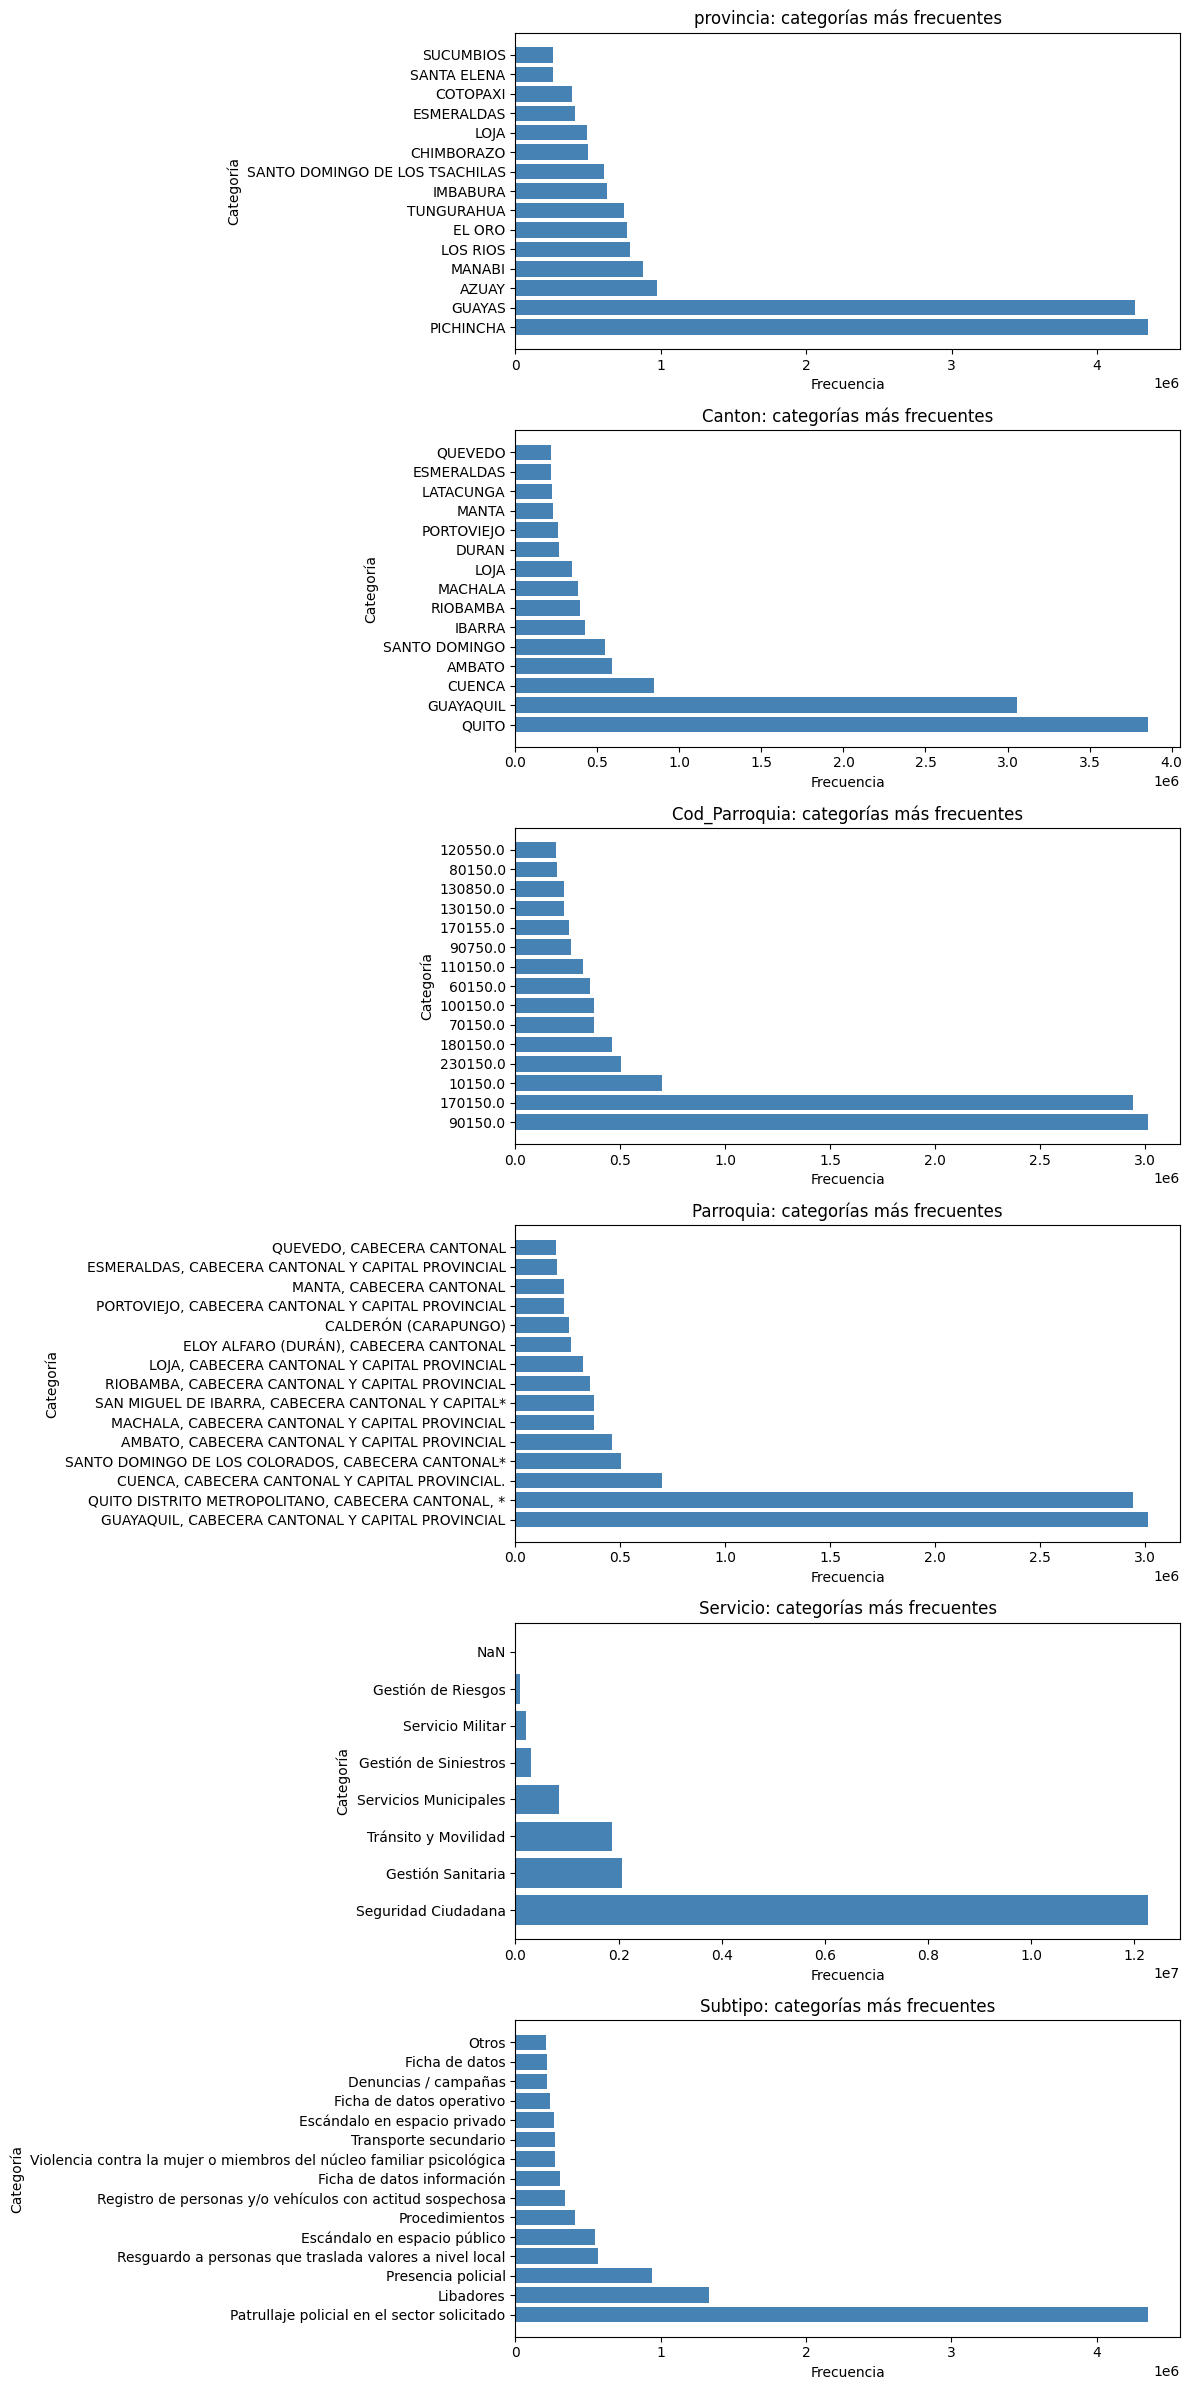

,variable_1,variable_2,chi2,p_value,grados_libertad,V_Cramer,esperados_menores_5_pct
0,provincia,Canton,4.412532e+08,0.0,5575,0.999208,7.057005
1,provincia,Cod_Parroquia,4.419490e+08,0.0,26025,0.999996,23.770855
2,provincia,Parroquia,4.355634e+08,0.0,24475,0.992745,23.222135
3,provincia,Servicio,1.633520e+06,0.0,156,0.124099,3.174603
4,provincia,Subtipo,1.419748e+07,0.0,17992,0.175742,43.487788
5,Canton,Cod_Parroquia,3.924498e+09,0.0,232143,0.997750,68.383260
6,Canton,Parroquia,3.838923e+09,0.0,218317,0.986812,67.175656
7,Canton,Servicio,2.609487e+06,0.0,1344,0.156850,0.698413
8,Canton,Subtipo,2.369877e+07,0.0,155008,0.077356,71.281706
9,Cod_Parroquia,Parroquia,1.729352e+10,0.0,1020118,0.999614,89.004442


Subtipo,Abandono de adultos mayores,"Abandono de niños, niñas o adolescentes",Abandono de persona,Abastecimiento de agua,Abigeato,Abrir viviendas / vehículos,Abuso de confianza,Abuso sexual,Accidente de tránsito,Accidente de tránsito con heridos,...,Vigilancia y mantenimiento de hitos,Explotación y transporte ilegal de madera,Entrenamiento en aeronaves,Movimientos sísmicos,Embarcaciones marítimas,Turismo sexual,Gestión de Siniestros,Servicio Militar,,Tsunami
Servicio,,,,,,,,,,,,,,,,,,,,,
NaN,0,0,0,1,0,5,1,0,5,15,...,0,0,0,0,0,0,0,0,0,0
Gestión Sanitaria,0,0,0,0,0,0,0,0,30533,0,...,0,0,0,0,0,0,583,0,0,0
Gestión de Riesgos,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,2
Gestión de Siniestros,0,0,0,1612,0,11884,0,0,65,0,...,0,0,0,0,0,0,4146,0,0,0
Seguridad Ciudadana,258,1461,6130,0,3699,0,12527,4749,0,360,...,0,0,0,0,0,4,0,0,1,0
Servicio Militar,0,0,0,3,0,0,0,0,0,0,...,11,2,3,1,2,0,0,2409,0,0
Servicios Municipales,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Tránsito y Movilidad,0,0,0,0,0,0,0,0,0,103961,...,0,0,0,0,0,0,0,0,0,0


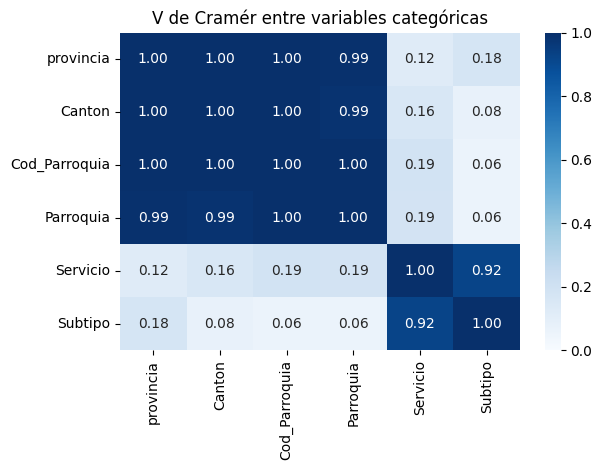

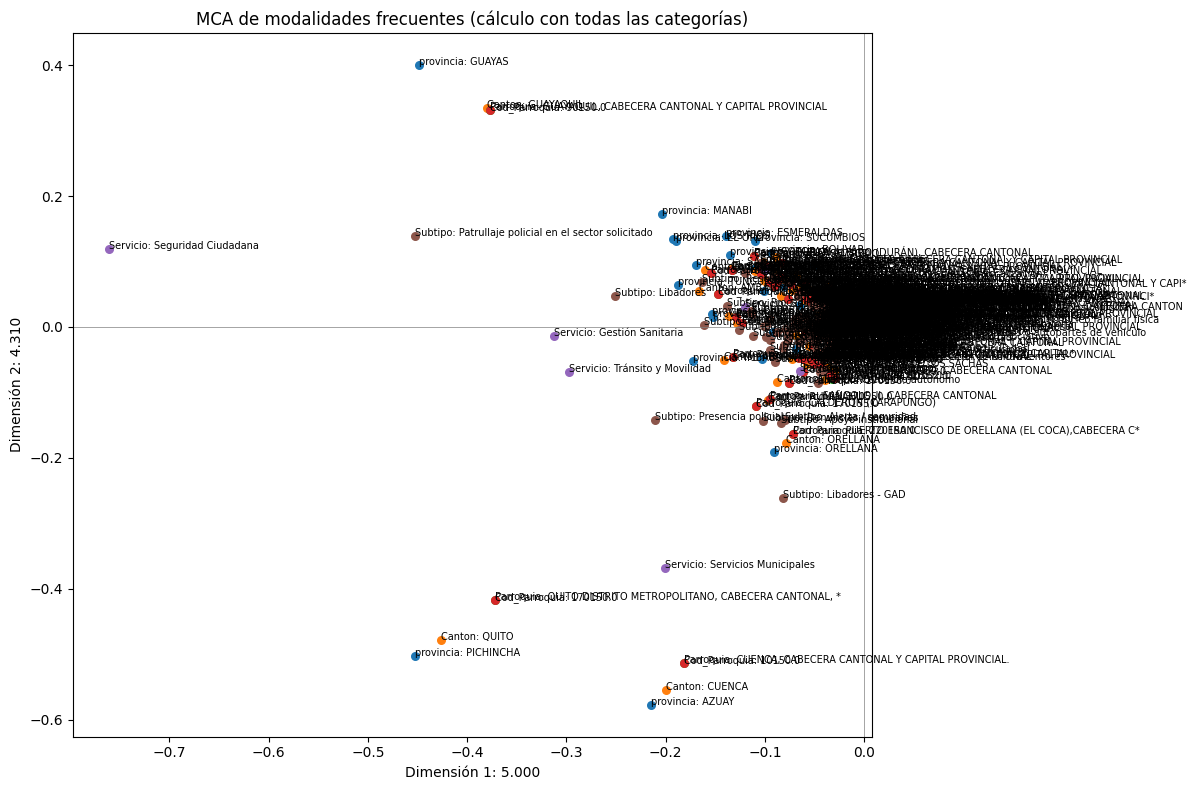

frecuencia  \
provincia                      Canton        Cod_Parroquia Parroquia                                          Servicio              Subtipo                                                          
GUAYAS                         GUAYAQUIL     90150.0       GUAYAQUIL, CABECERA CANTONAL Y CAPITAL PROVINCIAL  Seguridad Ciudadana   Patrullaje policial en el sector solicitado             968484   
PICHINCHA                      QUITO         170150.0      QUITO DISTRITO METROPOLITANO, CABECERA CANTONAL, * Seguridad Ciudadana   Patrullaje policial en el sector solicitado             470649   
                                                                                                                                    Presencia policial                                      347460   
GUAYAS                         GUAYAQUIL     90150.0       GUAYAQUIL, CABECERA CANTONAL Y CAPITAL PROVINCIAL  Seguridad Ciudadana   Libadores                                               222079   
PICHINCHA                      QUITO         170150.0      QUITO DISTRITO METROPOLITANO, CABECERA CANTONAL, * Seguridad Ciudadana   Libadores                                               220388   
AZUAY                          CUENCA        10150.0       CUENCA, CABECERA CANTONAL Y CAPITAL PROVINCIAL.    Seguridad Ciudadana   Patrullaje policial en el sector solicitado             148494   
SANTO DOMINGO DE LOS TSACHILAS SANTO DOMINGO 230150.0      SANTO DOMINGO DE LOS COLORADOS, CABECERA CANTONAL* Seguridad Ciudadana   Patrullaje policial en el sector solicitado             141735   
PICHINCHA                      QUITO         170150.0      QUITO DISTRITO METROPOLITANO, CABECERA CANTONAL, * Seguridad Ciudadana   Escándalo en espacio público                            127351   
GUAYAS                         GUAYAQUIL     90150.0       GUAYAQUIL, CABECERA CANTONAL Y CAPITAL PROVINCIAL  Seguridad Ciudadana   Presencia policial                                      115578   
TUNGURAHUA                     AMBATO        180150.0      AMBATO, CABECERA CANTONAL Y CAPITAL PROVINCIAL     Seguridad Ciudadana   Patrullaje policial en el sector solicitado             107169   
EL ORO                         MACHALA       70150.0       MACHALA, CABECERA CANTONAL Y CAPITAL PROVINCIAL    Seguridad Ciudadana   Patrullaje policial en el sector solicitado             106488   
CHIMBORAZO                     RIOBAMBA      60150.0       RIOBAMBA, CABECERA CANTONAL Y CAPITAL PROVINCIAL   Seguridad Ciudadana   Patrullaje policial en el sector solicitado             106034   
GUAYAS                         GUAYAQUIL     90150.0       GUAYAQUIL, CABECERA CANTONAL Y CAPITAL PROVINCIAL  Seguridad Ciudadana   Consumo de sustancias sujetas a fiscalización           105993   
AZUAY                          CUENCA        10150.0       CUENCA, CABECERA CANTONAL Y CAPITAL PROVINCIAL.    Servicios Municipales Libadores - GAD                                         102099   
LOJA                           LOJA          110150.0      LOJA, CABECERA CANTONAL Y CAPITAL PROVINCIAL       Seguridad Ciudadana   Patrullaje policial en el sector solicitado              99232   
GUAYAS                         GUAYAQUIL     90150.0       GUAYAQUIL, CABECERA CANTONAL Y CAPITAL PROVINCIAL  Tránsito y Movilidad  Procedimientos                                           88440   
PICHINCHA                      QUITO         170150.0      QUITO DISTRITO METROPOLITANO, CABECERA CANTONAL, * Servicios Municipales Apoyo institucional                                      88070   
GUAYAS                         DURAN         90750.0       ELOY ALFARO (DURÁN), CABECERA CANTONAL             Seguridad Ciudadana   Patrullaje policial en el sector solicitado              85117   
IMBABURA                       IBARRA        100150.0      SAN MIGUEL DE IBARRA, CABECERA CANTONAL Y CAPITAL* Seguridad Ciudadana   Patrullaje policial en el sector solicitado              84540   
PICHINCHA                 

In [3]:
# Preparar contenedores para conservar las tablas completas de frecuencias y contingencia.
frecuencias_eda = {}
filas_univariadas = []

# Calcular frecuencias, porcentajes, moda, entropía y Gini para cada campo categórico.
for columna in COLUMNAS_CATEGORICAS:
    conteos = df[columna].value_counts(dropna=False)
    frecuencias_eda[columna] = pd.DataFrame({'frecuencia': conteos, 'porcentaje': conteos / len(df) * 100})
    proporciones = conteos / len(df)
    filas_univariadas.append({
        'variable': columna,
        'cardinalidad': len(conteos),
        'moda': conteos.index[0] if len(conteos) else None,
        'porcentaje_moda': proporciones.iloc[0] * 100 if len(conteos) else np.nan,
        'entropia_bits': -(proporciones * np.log2(proporciones)).sum(),
        'gini': 1 - (proporciones ** 2).sum()
    })

# Crear y mostrar el resumen univariado calculado con todas las filas.
resumen_univariado = pd.DataFrame(filas_univariadas).set_index('variable')
display(resumen_univariado)

# Mostrar las tablas completas de frecuencias para las variables con cardinalidad manejable.
for columna in ['provincia', 'Servicio', 'Subtipo']:
    print(f'Frecuencias completas: {columna}')
    display(frecuencias_eda[columna])

# Graficar las quince categorías más frecuentes para mantener legible la presentación.
fig, axes = plt.subplots(len(COLUMNAS_CATEGORICAS), 1, figsize=(12, 4 * len(COLUMNAS_CATEGORICAS)))
for eje, columna in zip(axes, COLUMNAS_CATEGORICAS):
    datos = frecuencias_eda[columna].head(15).sort_values('frecuencia')
    etiquetas = [str(valor) if pd.notna(valor) else 'NaN' for valor in datos.index.to_numpy()]
    posiciones = np.arange(len(etiquetas))
    eje.barh(posiciones, datos['frecuencia'].astype(float), color='steelblue')
    eje.set_yticks(posiciones)
    eje.set_yticklabels(etiquetas)
    eje.invert_yaxis()
    eje.set(title=f'{columna}: categorías más frecuentes', xlabel='Frecuencia', ylabel='Categoría')
plt.tight_layout()
plt.show()

# Calcular las tablas cruzadas exactas para cada pareja de variables categóricas.
from itertools import combinations
tablas_contingencia = {}
filas_asociacion = []
for columna_a, columna_b in combinations(COLUMNAS_CATEGORICAS, 2):
    tabla = pd.crosstab(df[columna_a], df[columna_b], dropna=False)
    tablas_contingencia[(columna_a, columna_b)] = tabla
    # Eliminar filas/columnas vacías antes del test chi-cuadrado para evitar
    # que chi2_contingency reciba celdas esperadas con valor 0.
    tabla = tabla.loc[tabla.sum(axis=1) > 0, tabla.sum(axis=0) > 0]
    if tabla.shape[0] < 2 or tabla.shape[1] < 2:
        continue
    tablas_contingencia[(columna_a, columna_b)] = tabla
    chi2, valor_p, grados_libertad, esperados = chi2_contingency(tabla.to_numpy())
    denominador = tabla.to_numpy().sum() * min(tabla.shape[0] - 1, tabla.shape[1] - 1)
    v_cramer = np.sqrt(chi2 / denominador) if denominador > 0 else np.nan
    filas_asociacion.append({
        'variable_1': columna_a,
        'variable_2': columna_b,
        'chi2': chi2,
        'p_value': valor_p,
        'grados_libertad': grados_libertad,
        'V_Cramer': v_cramer,
        'esperados_menores_5_pct': (esperados < 5).mean() * 100
    })

# Mostrar los resultados de asociación y un cruce representativo completo.
resultados_asociacion = pd.DataFrame(filas_asociacion)
display(resultados_asociacion)
display(tablas_contingencia[('Servicio', 'Subtipo')])

# Preparar el mapa de calor de V de Cramér para comparar la fuerza de asociación.
matriz_cramer = pd.DataFrame(np.eye(len(COLUMNAS_CATEGORICAS)), index=COLUMNAS_CATEGORICAS, columns=COLUMNAS_CATEGORICAS)
for _, fila in resultados_asociacion.iterrows():
    matriz_cramer.loc[fila['variable_1'], fila['variable_2']] = fila['V_Cramer']
    matriz_cramer.loc[fila['variable_2'], fila['variable_1']] = fila['V_Cramer']
sns.heatmap(matriz_cramer, annot=True, fmt='.2f', vmin=0, vmax=1, cmap='Blues')
plt.title('V de Cramér entre variables categóricas')
plt.tight_layout()
plt.show()

# Construir el índice de cada modalidad y su masa marginal para la matriz de Burt.
indice_modalidad = {}
frecuencias_modalidad = []
for columna in COLUMNAS_CATEGORICAS:
    conteos = df[columna].value_counts(dropna=False)
    for categoria, frecuencia in conteos.items():
        indice_modalidad[(columna, categoria)] = len(indice_modalidad)
        frecuencias_modalidad.append(int(frecuencia))

# Agregar diagonal de Burt y asociaciones simétricas utilizando solo celdas no nulas.
filas_burt, columnas_burt, valores_burt = [], [], []
for columna in COLUMNAS_CATEGORICAS:
    for categoria, frecuencia in df[columna].value_counts(dropna=False).items():
        posicion = indice_modalidad[(columna, categoria)]
        filas_burt.append(posicion)
        columnas_burt.append(posicion)
        valores_burt.append(int(frecuencia))
for (columna_a, columna_b), tabla in tablas_contingencia.items():
    valores = tabla.to_numpy()
    indices_a, indices_b = np.nonzero(valores)
    for indice_a, indice_b in zip(indices_a, indices_b):
        a = indice_modalidad[(columna_a, tabla.index[indice_a])]
        b = indice_modalidad[(columna_b, tabla.columns[indice_b])]
        cuenta = int(valores[indice_a, indice_b])
        filas_burt.extend([a, b])
        columnas_burt.extend([b, a])
        valores_burt.extend([cuenta, cuenta])
matriz_burt = coo_matrix((valores_burt, (filas_burt, columnas_burt)), shape=(len(indice_modalidad), len(indice_modalidad))).tocsr()

# Definir el operador MCA centrado para resolver los dos ejes con una matriz dispersa.
masas = np.asarray(frecuencias_modalidad, dtype=float) / (len(df) * len(COLUMNAS_CATEGORICAS))
raiz_masas = np.sqrt(masas)
inversa_raiz_masas = 1 / raiz_masas
factor_burt = len(df) * len(COLUMNAS_CATEGORICAS)
def aplicar_mca(vector):
    vector_ajustado = inversa_raiz_masas * vector
    producto = matriz_burt.dot(vector_ajustado) / factor_burt
    return inversa_raiz_masas * producto - raiz_masas * np.dot(raiz_masas, vector)

# Calcular y graficar las dos dimensiones de las modalidades categóricas.
if len(indice_modalidad) > 2:
    operador_mca = LinearOperator(matriz_burt.shape, matvec=aplicar_mca, dtype=float)
    valores_mca, vectores_mca = eigsh(operador_mca, k=2, which='LA')
    orden_mca = np.argsort(valores_mca)[::-1]
    valores_mca = valores_mca[orden_mca]
    coordenadas_mca = vectores_mca[:, orden_mca] * np.sqrt(np.maximum(valores_mca, 0))
    fig, ax = plt.subplots(figsize=(12, 8))
    colores_mca = dict(zip(COLUMNAS_CATEGORICAS, sns.color_palette('tab10', len(COLUMNAS_CATEGORICAS))))
    for (columna, categoria), posicion in indice_modalidad.items():
        frecuencia = frecuencias_modalidad[posicion]
        if frecuencia >= len(df) * 0.001:
            x, y = coordenadas_mca[posicion]
            ax.scatter(x, y, color=colores_mca[columna], s=30)
            ax.annotate(f'{columna}: {categoria}', (x, y), fontsize=7)
    ax.axhline(0, color='gray', linewidth=0.5)
    ax.axvline(0, color='gray', linewidth=0.5)
    ax.set(title='MCA de modalidades frecuentes (cálculo con todas las categorías)', xlabel=f'Dimensión 1: {valores_mca[0]:.3f}', ylabel=f'Dimensión 2: {valores_mca[1]:.3f}')
    plt.tight_layout()
    plt.show()

# Identificar perfiles conjuntos más frecuentes para describir co-ocurrencias.
perfiles = df.groupby(COLUMNAS_CATEGORICAS, observed=True, sort=False).size().nlargest(20).to_frame('frecuencia')
perfiles['porcentaje'] = perfiles['frecuencia'] / len(df) * 100
display(perfiles)

### Hallazgos y análisis

Las salidas muestran distribución, diversidad y relaciones entre las seis variables categóricas. Un p-value pequeño no implica una asociación fuerte cuando hay millones de registros; debe interpretarse junto con V de Cramér y con el porcentaje de celdas con frecuencia esperada menor que cinco. El MCA representa modalidades, no filas, y el gráfico omite solo etiquetas de categorías raras para ser legible; perfiles y estadísticas se calculan con todas las filas.

**Conclusión.** El EDA cuantifica frecuencias, cardinalidad, desequilibrio y asociaciones sin expandir todas las filas a variables dummy densas. Las categorías cercanas en el MCA y los perfiles frecuentes son patrones descriptivos, no evidencia causal ni segmentos de un modelo entrenado.

## 4. Valores faltantes

Se cuantifican ausencias y cadenas vacías por variable. Para los campos categóricos se conserva explícitamente la ausencia como `SIN DATO`; en la fecha se conserva `NaT` para no inventar información temporal. La ausencia aleatoria no puede probarse únicamente con un resumen de valores.

,faltantes,porcentaje
Fecha,0,0.000000
provincia,2144,0.012127
Canton,2144,0.012127
Cod_Parroquia,2148,0.012149
Parroquia,2144,0.012127
Servicio,2221,0.012562
Subtipo,89,0.000498


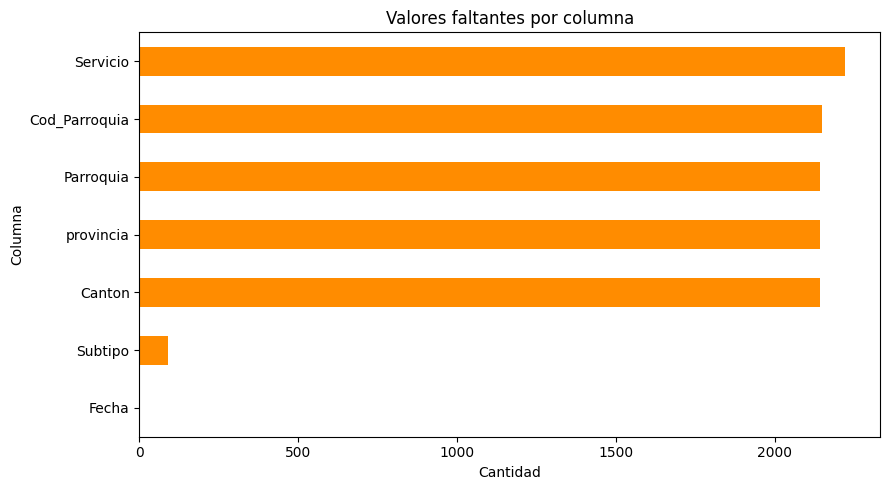

,faltantes_finales
Fecha,0
provincia,0
Canton,0
Cod_Parroquia,0
Parroquia,0
Servicio,0
Subtipo,0


In [4]:
# Contar valores nulos y mostrar la proporción antes de cualquier imputación.
resumen_faltantes = pd.DataFrame({
    'faltantes': df.isna().sum(),
    'porcentaje': df.isna().mean() * 100
})

# Mostrar también los niveles vacíos si el archivo los contiene como texto.
for columna in COLUMNAS_CATEGORICAS:
    niveles_vacios = [nivel for nivel in df[columna].cat.categories if str(nivel).strip() == '']
    if niveles_vacios:
        resumen_faltantes.loc[columna, 'faltantes'] += int(df[columna].isin(niveles_vacios).sum())

# Presentar el resumen y el gráfico de ausencias observadas.
display(resumen_faltantes)
ax = resumen_faltantes['faltantes'].sort_values().plot.barh(figsize=(9, 5), color='darkorange')
ax.set(title='Valores faltantes por columna', xlabel='Cantidad', ylabel='Columna')
plt.tight_layout()
plt.show()

# Reemplazar nulos categóricos por una categoría identificable sin imputar la fecha.
for columna in COLUMNAS_CATEGORICAS:
    serie = df[columna]
    if 'SIN DATO' not in serie.cat.categories:
        df[columna] = serie.cat.add_categories(['SIN DATO'])
    df[columna] = df[columna].fillna('SIN DATO')

# Confirmar las ausencias restantes después del tratamiento categórico.
display(pd.DataFrame({'faltantes_finales': df.isna().sum()}))

### Hallazgos y análisis

La tabla y el gráfico cuantifican dónde se concentran los faltantes. La categoría `SIN DATO` evita confundir ausencia con una categoría válida como `NO APLICA`. Las fechas ausentes quedan sin imputar. Para evaluar si la ausencia depende de otras variables se necesitaría analizar esos patrones y conocer el proceso de captura; el porcentaje por sí solo no demuestra aleatoriedad.

**Conclusión.** Los faltantes categóricos quedan explícitos y los faltantes de fecha se mantienen como ausencias reales. No se eliminan filas, de modo que el dataset conserva su cobertura original.

## 5. Outliers y valores atípicos

Las categorías no poseen outliers numéricos; se buscan niveles muy raros como posibles errores o eventos infrecuentes, sin eliminarlos automáticamente. Para la fecha se revisan el rango temporal y los registros por mes. El criterio de rareza es descriptivo y debe validarse con el dominio.

,categorias_totales,categorias_menores_0_1_pct,registros_en_categorias_raras,ejemplos
variable,,,,
provincia,27,3,5917,"[ZONA NO DELIMITADA, SIN DATO, 0]"
Canton,225,126,1017922,"[BABA, CALVAS, MERA, TOSAGUA, CAMILO PONCE ENR..."
Cod_Parroquia,1043,931,2672586,"[170165.0, 170170.0, 130250.0, 170176.0, 22035..."
Parroquia,981,867,2575991,"[LLANO CHICO, NAYÓN, CALCETA, CABECERA CANTONA..."
Servicio,8,1,2221,[SIN DATO]
Subtipo,694,584,1197125,"[Conato, Evento cerebro vascular, Paro cardiac..."


,fecha_minima,fecha_maxima,fechas_no_interpretadas
0,2021-07-01,2026-08-31,0


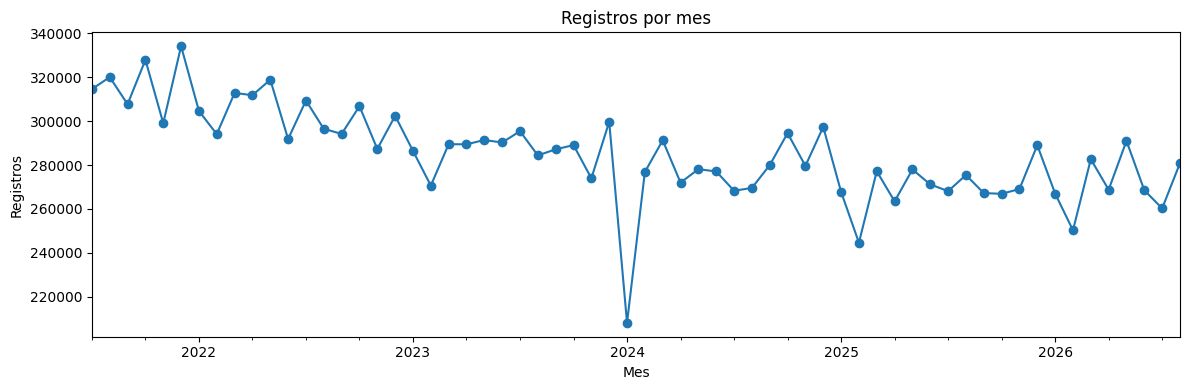

In [5]:
# Definir el umbral descriptivo de rareza como menos del 0,1 por ciento de los registros.
UMBRAL_RAREZA = 0.001
filas_rareza = []

# Contar las categorías raras de cada campo y guardar ejemplos para revisión.
for columna in COLUMNAS_CATEGORICAS:
    conteos = df[columna].value_counts(dropna=False)
    raras = conteos[conteos / len(df) < UMBRAL_RAREZA]
    filas_rareza.append({
        'variable': columna,
        'categorias_totales': len(conteos),
        'categorias_menores_0_1_pct': len(raras),
        'registros_en_categorias_raras': int(raras.sum()),
        'ejemplos': list(raras.head(5).index)
    })

# Revisar el rango temporal y el conteo de registros por mes calendario.
fechas_analisis = pd.to_datetime(df['Fecha'].astype('string'), format='mixed', dayfirst=True, errors='coerce')
resumen_temporal = pd.DataFrame({
    'fecha_minima': [fechas_analisis.min()],
    'fecha_maxima': [fechas_analisis.max()],
    'fechas_no_interpretadas': [int(fechas_analisis.isna().sum())]
})
registros_mes = fechas_analisis.dt.to_period('M').value_counts().sort_index()

# Mostrar diagnósticos y visualizar el volumen mensual, conservando los niveles raros.
display(pd.DataFrame(filas_rareza).set_index('variable'))
display(resumen_temporal)
registros_mes.plot(figsize=(12, 4), marker='o')
plt.title('Registros por mes')
plt.xlabel('Mes')
plt.ylabel('Registros')
plt.tight_layout()
plt.show()

# Liberar la conversión temporal temporal; la columna original aún no ha sido reemplazada.
del fechas_analisis

### Hallazgos y análisis

La salida identifica categorías por debajo del 0,1% y muestra ejemplos, además del rango de fechas y el volumen mensual. Una categoría rara puede corresponder a una emergencia real, no a un error. Sin límites temporales de negocio, no se descartan fechas solo por ser antiguas o futuras; los valores que no puedan convertirse se reportan como incidencias de formato.

**Conclusión.** Los casos raros quedan señalados para validación, no eliminados. No hay una regla estadística apropiada para retirar observaciones atípicas de campos nominales sin información de contexto.

## 6. Limpieza

Se normalizan mayúsculas, espacios y formato de los campos categóricos; la fecha se convierte a tipo datetime y el código geográfico se mantiene como identificador textual. No se corrigen topónimos por similitud ni se eliminan duplicados sin una regla oficial, para evitar combinar categorías o eventos diferentes.

In [6]:
# Guardar las cardinalidades previas para documentar el efecto de la normalización.
cardinalidad_antes = df[COLUMNAS_CATEGORICAS].nunique(dropna=False)

# Normalizar niveles de una columna categórica sin expandir los códigos de todos los registros a texto.
def normalizar_categoria(serie):
    categorias_originales = list(serie.cat.categories)
    categorias_limpias = [' '.join(str(valor).strip().upper().split()) for valor in categorias_originales]
    categorias_unicas = pd.Index(categorias_limpias).drop_duplicates().tolist()
    mapa_codigos = pd.Index(categorias_unicas).get_indexer(categorias_limpias)
    codigos_fila = serie.cat.codes.to_numpy(copy=True)
    validos = codigos_fila >= 0
    codigos_fila[validos] = mapa_codigos[codigos_fila[validos]]
    return pd.Series(pd.Categorical.from_codes(codigos_fila, categories=categorias_unicas), index=serie.index, name=serie.name)

# Aplicar limpieza de espacios y mayúsculas a las variables categóricas.
for columna in COLUMNAS_CATEGORICAS:
    df[columna] = normalizar_categoria(df[columna])

# Normalizar el código parroquial como texto y eliminar el sufijo decimal introducido por algunas exportaciones.
df['Cod_Parroquia'] = df['Cod_Parroquia'].cat.rename_categories(
    lambda valor: str(valor).strip().removesuffix('.0')
)

# Convertir valores únicos de fecha una sola vez y mapearlos a las filas mediante códigos categóricos.
codigos_fecha = df['Fecha'].cat.codes.to_numpy(copy=True)
fechas_categoria = pd.to_datetime(pd.Index(df['Fecha'].cat.categories), format='mixed', dayfirst=True, errors='coerce')
fechas_validas = fechas_categoria.dropna().unique().sort_values()
mapa_fecha = pd.Index(fechas_validas).get_indexer(fechas_categoria)
codigos_fecha_validos = np.full(len(codigos_fecha), -1, dtype=np.int32)
mascara_fecha = codigos_fecha >= 0
codigos_fecha_validos[mascara_fecha] = mapa_fecha[codigos_fecha[mascara_fecha]]
df['Fecha'] = pd.Series(pd.Categorical.from_codes(codigos_fecha_validos, categories=fechas_validas), index=df.index).astype('datetime64[ns]')

# Comparar cardinalidades y mostrar el esquema limpio.
cardinalidad_despues = df[COLUMNAS_CATEGORICAS].nunique(dropna=False)
display(pd.DataFrame({'antes': cardinalidad_antes, 'despues': cardinalidad_despues}))
display(df.dtypes.to_frame('tipo_despues_de_limpieza'))
print(f'Duplicados exactos conservados para validación: {int(df.duplicated().sum()):,}')

,antes,despues
provincia,27,27
Canton,225,225
Cod_Parroquia,1043,1043
Parroquia,981,981
Servicio,8,8
Subtipo,694,692


,tipo_despues_de_limpieza
Fecha,datetime64[ns]
provincia,category
Canton,category
Cod_Parroquia,category
Parroquia,category
Servicio,category
Subtipo,category


Duplicados exactos conservados para validación: 11,745,420


### Hallazgos y análisis

La comparación de cardinalidad permite ver si variantes de mayúsculas y espacios se unificaron. El código parroquial permanece textual, así que no se realizan operaciones aritméticas sobre él. Las filas exactamente duplicadas se conservan y se reportan: una clave de incidente o una regla de deduplicación de la fuente es necesaria para decidir si representan redundancia real.

**Conclusión.** Se estandariza formato sin introducir correcciones geográficas especulativas. `Fecha` queda como fecha, las demás columnas categóricas siguen comprimidas y la información original se conserva en memoria.

## 7. Ingeniería de características

A partir de `Fecha` se derivan año, mes, día de la semana y días transcurridos desde la primera fecha observada. Las características temporales facilitan estudiar tendencias y estacionalidad. No se derivan variables del futuro ni se transforma el código geográfico en una magnitud numérica.

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Anio,17680253.0,<NA>,<NA>,<NA>,2023.500024,1.552078,2021.0,2022.0,2023.0,2025.0,2026.0
Mes,17680253.0,12.0,8.0,1726694.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dia_Semana,17680253.0,7.0,6.0,3183294.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dias_Desde_Inicio,17680253.0,NaN,NaN,NaN,916.814758,549.121643,0.0,435.0,899.0,1392.0,1887.0


,Anio,Mes,registros
0,2021,7,314507
1,2021,8,319989
2,2021,9,307665
3,2021,10,327820
4,2021,11,299013
5,2021,12,334055
6,2022,1,304575
7,2022,2,294034
8,2022,3,312801
9,2022,4,311739


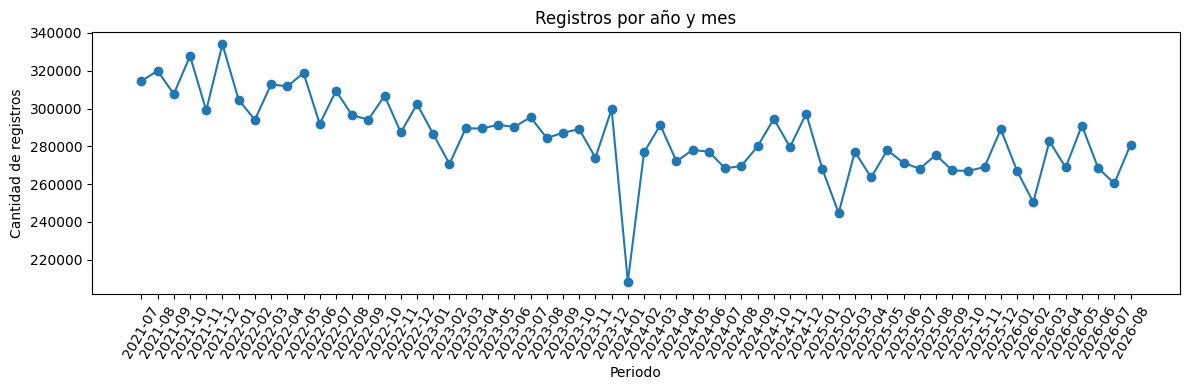

In [7]:
# Calcular el origen temporal a partir de la fecha válida más antigua.
fecha_origen = df['Fecha'].min()

# Crear atributos calendarios categóricos que pueden modelar patrones estacionales.
df['Anio'] = df['Fecha'].dt.year.astype('Int16')
df['Mes'] = df['Fecha'].dt.month.astype('Int8').astype('category')
df['Dia_Semana'] = df['Fecha'].dt.dayofweek.astype('Int8').astype('category')

# Crear una variable numérica de tiempo transcurrido, conservando faltantes cuando falta la fecha.
df['Dias_Desde_Inicio'] = (df['Fecha'] - fecha_origen).dt.days.astype('float32')

# Resumir las nuevas variables y visualizar los conteos mensuales.
display(df[['Anio', 'Mes', 'Dia_Semana', 'Dias_Desde_Inicio']].describe(include='all').T)
conteo_mensual = df.groupby(['Anio', 'Mes'], observed=True).size().rename('registros').reset_index()
display(conteo_mensual.head(24))
conteo_mensual['periodo'] = conteo_mensual['Anio'].astype(str) + '-' + conteo_mensual['Mes'].astype(str).str.zfill(2)
plt.figure(figsize=(12, 4))
plt.plot(conteo_mensual['periodo'], conteo_mensual['registros'], marker='o')
plt.title('Registros por año y mes')
plt.xlabel('Periodo')
plt.ylabel('Cantidad de registros')
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

### Hallazgos y análisis

La tabla describe los campos temporales y la gráfica presenta el volumen mensual. Un patrón estacional puede orientar la selección de variables y la estrategia de validación temporal. Los registros sin fecha conservan valores faltantes en las variables derivadas; no se les asigna una fecha artificial.

**Conclusión.** Se agregan características de calendario y tiempo transcurrido sin eliminar observaciones. En un modelo de pronóstico, la partición de entrenamiento y prueba debe respetar el orden temporal para evitar fuga de información.

## 8. Codificación

Las variables nominales se preparan para codificación One-Hot mediante `OneHotEncoder`, que genera una matriz dispersa. Por el tamaño del dataset no se expande todo el conjunto a millones de filas dummy en memoria; se define el vocabulario completo de categorías y se muestra una pequeña transformación de ejemplo.

Cantidad de columnas One-Hot posibles: 2,995
Tamaño disperso del ejemplo: (5, 2995)


,ejemplo_de_columna
0,provincia_AZUAY
1,provincia_BOLIVAR
2,provincia_CARCHI
3,provincia_CAÑAR
4,provincia_CHIMBORAZO
5,provincia_COTOPAXI
6,provincia_EL ORO
7,provincia_ESMERALDAS
8,provincia_GUAYAS
9,provincia_IMBABURA


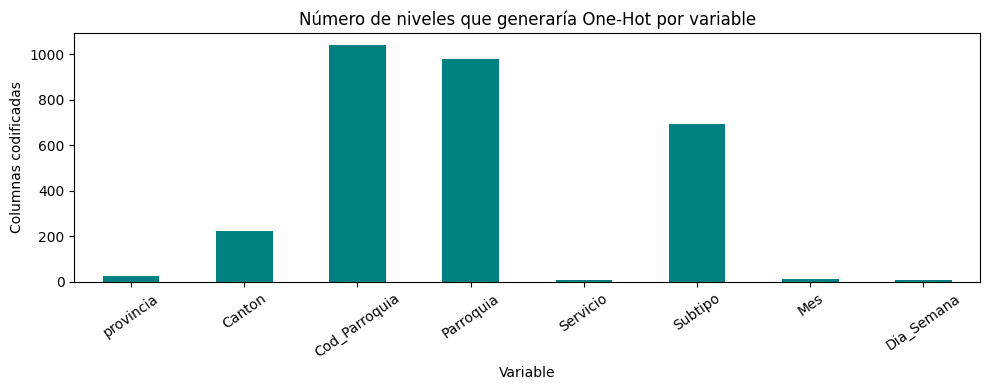

In [8]:
# Definir las columnas categóricas que serán candidatas a variables predictoras.
COLUMNAS_MODELO_CATEGORICAS = COLUMNAS_CATEGORICAS + ['Mes', 'Dia_Semana']

# Obtener el vocabulario completo directamente de las categorías sin crear una matriz por registro.
vocabularios = [list(df[columna].cat.categories) for columna in COLUMNAS_MODELO_CATEGORICAS]

# Crear un codificador disperso que ignore niveles no vistos en datos futuros.
codificador = OneHotEncoder(categories=vocabularios, handle_unknown='ignore', sparse_output=True, dtype=np.uint8)

# Ajustar la estructura del codificador con una fila; las categorías completas ya se especificaron arriba.
codificador.fit(df[COLUMNAS_MODELO_CATEGORICAS].head(1))

# Transformar únicamente cinco filas para validar el formato disperso y los nombres de las columnas.
muestra_codificada = codificador.transform(df[COLUMNAS_MODELO_CATEGORICAS].head(5))
nombres_codificados = codificador.get_feature_names_out(COLUMNAS_MODELO_CATEGORICAS)
print(f'Cantidad de columnas One-Hot posibles: {len(nombres_codificados):,}')
print(f'Tamaño disperso del ejemplo: {muestra_codificada.shape}')
display(pd.DataFrame({'ejemplo_de_columna': nombres_codificados[:30]}))

# Visualizar cuántas columnas codificadas corresponden a cada variable original.
conteo_codificado = pd.Series({columna: len(vocabulario) for columna, vocabulario in zip(COLUMNAS_MODELO_CATEGORICAS, vocabularios)})
conteo_codificado.plot.bar(figsize=(10, 4), color='teal')
plt.title('Número de niveles que generaría One-Hot por variable')
plt.xlabel('Variable')
plt.ylabel('Columnas codificadas')
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

### Hallazgos y análisis

El número de columnas potenciales muestra cómo la cardinalidad afecta el tamaño de la representación. One-Hot es adecuado para categorías nominales, pero códigos geográficos de alta cardinalidad pueden producir muchas columnas. El ejemplo solo transforma cinco filas; no es una muestra de análisis ni reemplaza el dataset completo. En una evaluación supervisada, el codificador debe ajustarse con el conjunto de entrenamiento.

**Conclusión.** El codificador y el vocabulario quedan definidos dentro del notebook. La matriz completa no se materializa para proteger la memoria; puede transformarse por lotes durante el entrenamiento de un modelo o dentro de un pipeline.

## 9. Escalado

Se estandariza la variable numérica de tiempo transcurrido mediante media y desviación estándar. El ajuste se realiza por bloques para evitar una copia completa de los datos. Las variables One-Hot no se escalan; antes de evaluar un modelo, el escalador debe ajustarse solo con los datos de entrenamiento.

,media,desviacion
Dias_Desde_Inicio,916.814643,549.121604


,Dias_Desde_Inicio_escalada
0,1.047464
1,1.047464
2,1.047464
3,1.047464
4,1.047464
5,1.047464
6,1.047464
7,1.047464
8,1.047464
9,1.047464


,original,escalado
0,1492.0,1.047464
1,1492.0,1.047464
2,1492.0,1.047464
3,1492.0,1.047464
4,1492.0,1.047464
5,1492.0,1.047464
6,1492.0,1.047464
7,1492.0,1.047464
8,1492.0,1.047464
9,1492.0,1.047464


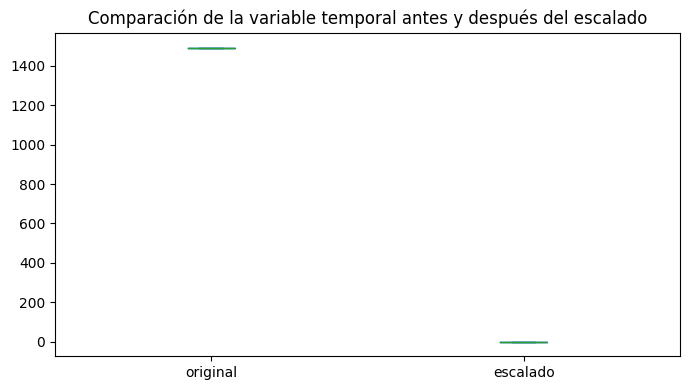

In [9]:
# Definir las columnas numéricas que se escalarán y crear el escalador estándar.
COLUMNAS_MODELO_NUMERICAS = ['Dias_Desde_Inicio']
escalador = StandardScaler()
TAMANO_BLOQUE = 250_000

# Ajustar media y desviación con bloques de valores válidos para reducir memoria temporal.
for inicio in range(0, len(df), TAMANO_BLOQUE):
    bloque = df[COLUMNAS_MODELO_NUMERICAS].iloc[inicio:inicio + TAMANO_BLOQUE].dropna()
    if not bloque.empty:
        escalador.partial_fit(bloque)

# Mostrar parámetros aprendidos y verificar la transformación con algunos valores.
resumen_escalado = pd.DataFrame({'media': escalador.mean_, 'desviacion': escalador.scale_}, index=COLUMNAS_MODELO_NUMERICAS)
display(resumen_escalado)
muestra_escalada = escalador.transform(df[COLUMNAS_MODELO_NUMERICAS].head(10))
display(pd.DataFrame(muestra_escalada, columns=[f'{columna}_escalada' for columna in COLUMNAS_MODELO_NUMERICAS]))

# Comparar los rangos original y escalado para verificar que la transformación es razonable.
comparacion_escala = pd.DataFrame({
    'original': df['Dias_Desde_Inicio'].head(10).to_numpy(),
    'escalado': muestra_escalada[:, 0]
})
display(comparacion_escala)
comparacion_escala.plot(kind='box', figsize=(7, 4))
plt.title('Comparación de la variable temporal antes y después del escalado')
plt.tight_layout()
plt.show()

### Hallazgos y análisis

La tabla reporta la media y desviación calculadas sobre valores válidos; la vista y el diagrama de caja permiten revisar la transformación. Los valores faltantes de la fecha no participan en el ajuste. El escalado no cambia el orden relativo de las observaciones, pero centra y normaliza la escala de la característica temporal.

**Conclusión.** El escalador queda listo para la característica temporal y el ejemplo confirma el formato de salida. Para una estimación honesta del rendimiento, debe reajustarse dentro del conjunto de entrenamiento en cada partición, nunca con datos de prueba.

## 10. Dataset preparado

Se conforma el dataset analítico final con variables categóricas limpias y características temporales. Se inspeccionan tipos, faltantes, dimensiones y memoria. No se exporta ningún archivo y no se define una variable objetivo: para entrenar un modelo supervisado se requiere elegirla y establecer una partición de evaluación.

Filas preparadas: 17,680,253
Características disponibles: 10
Memoria del dataset final: 0.31 GiB


,tipo,faltantes
provincia,category,0
Canton,category,0
Cod_Parroquia,category,0
Parroquia,category,0
Servicio,category,0
Subtipo,category,0
Mes,category,0
Dia_Semana,category,0
Dias_Desde_Inicio,float32,0
Anio,Int16,0


,provincia,Canton,Cod_Parroquia,Parroquia,Servicio,Subtipo,Mes,Dia_Semana,Dias_Desde_Inicio,Anio
0,NAPO,ARCHIDONA,150350,"ARCHIDONA, CABECERA CANTONAL",SERVICIO MILITAR,SEGURIDAD EXTERIOR A C.P.L.,8,4,1492.0,2025
1,PICHINCHA,QUITO,170155,CALDERÓN (CARAPUNGO),SEGURIDAD CIUDADANA,APOYO A INSTITUCIONES ARTICULADAS,8,4,1492.0,2025
2,PICHINCHA,QUITO,170152,AMAGUAÑA,GESTIÓN SANITARIA,CONSULTA MÉDICA,8,4,1492.0,2025
3,PICHINCHA,QUITO,170150,"QUITO DISTRITO METROPOLITANO, CABECERA CANTONA...",TRÁNSITO Y MOVILIDAD,OTROS,8,4,1492.0,2025
4,PICHINCHA,QUITO,170175,PIFO,SEGURIDAD CIUDADANA,PRESENCIA POLICIAL,8,4,1492.0,2025


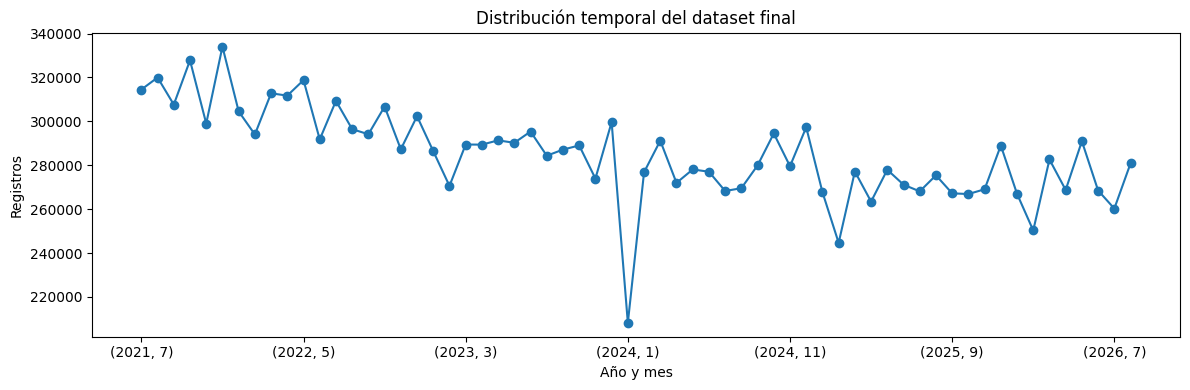

Predictores listos en X: (17680253, 10)
Variable objetivo definida: False
Codificador disperso y escalador disponibles como: codificador y escalador


In [10]:
# Definir las columnas disponibles como predictores, excluyendo la fecha original redundante.
COLUMNAS_DATASET_FINAL = COLUMNAS_MODELO_CATEGORICAS + COLUMNAS_MODELO_NUMERICAS + ['Anio']

# Crear el DataFrame final en memoria; las categorías siguen comprimidas y se conservan todas las filas.
df_modelo = df[COLUMNAS_DATASET_FINAL]

# Reservar explícitamente el objetivo como no definido para evitar entrenar una tarea inventada.
VARIABLE_OBJETIVO = None
X = df_modelo
y = None

# Presentar dimensiones, memoria, tipos y ausencias del dataset preparado.
print(f'Filas preparadas: {len(df_modelo):,}')
print(f'Características disponibles: {df_modelo.shape[1]}')
print(f'Memoria del dataset final: {df_modelo.memory_usage(deep=True).sum() / 1024**3:.2f} GiB')
display(pd.DataFrame({'tipo': df_modelo.dtypes.astype(str), 'faltantes': df_modelo.isna().sum()}))
display(df_modelo.head())

# Graficar la distribución temporal agregada como control visual del dataset final.
df_modelo.groupby(['Anio', 'Mes'], observed=True).size().plot(figsize=(12, 4), marker='o')
plt.title('Distribución temporal del dataset final')
plt.xlabel('Año y mes')
plt.ylabel('Registros')
plt.tight_layout()
plt.show()

# Informar los objetos disponibles para continuar con un pipeline de aprendizaje automático.
print(f'Predictores listos en X: {X.shape}')
print(f'Variable objetivo definida: {VARIABLE_OBJETIVO is not None}')
print('Codificador disperso y escalador disponibles como: codificador y escalador')

### Hallazgos y análisis

La última tabla confirma dimensiones, tipos y valores faltantes del dataset que se mantiene en memoria. `X` contiene los predictores sin expandir One-Hot sobre los 17 millones de registros; `codificador` y `escalador` definen las transformaciones para un pipeline posterior. `y` permanece vacío porque no se especificó cuál campo representa el resultado que se desea predecir.

**Conclusión.** El flujo deja preparado un dataset completo, limpio y eficiente en memoria para análisis y modelado. Antes de entrenar, debe definirse el objetivo, revisar que las variables disponibles sean válidas para esa predicción y ajustar codificación y escalado únicamente con el conjunto de entrenamiento. El notebook no crea archivos adicionales.

In [11]:
# Guardar el dataset preparado en la carpeta processed del proyecto.
RUTA_SALIDA = RUTA_DATASET.parents[1] / 'processed' / 'dataset_proyecto_preparado.csv'
RUTA_SALIDA.parent.mkdir(parents=True, exist_ok=True)

# Escribir por bloques para limitar el uso de memoria durante la exportación.
df_modelo.to_csv(
    RUTA_SALIDA,
    index=False,
    chunksize=TAMANO_BLOQUE,
    encoding='utf-8'
)

print(f'Dataset exportado: {RUTA_SALIDA}')

Dataset exportado: C:\Users\PAULA\Documents\IntegradorG3\data\processed\dataset_proyecto_preparado.csv


---
# Resumen #
### 1. Carga inicial del dataset
- Se cargó `data_proyecto.csv`conservando solo las columnas relevantes para el análisis.
- Las columnas categóricas se trataron como tipos categóricos para reducir memoria y preservar semántica.
- Los códigos geográficos se mantuvieron como texto, porque son identificadores y no magnitudes numéricas.
### 2. Inspección estructural
- Se revisaron dimensiones, tipos de dato, memoria ocupada, valores faltantes, duplicados y cardinalidad.
- Se identificó que Cod_Parroquia tiene alta cardinalidad y debe interpretarse como identificador, no como variable continua.
- Los duplicados se reportaron, pero no se eliminaron automáticamente porque puede haber registros legítimos repetidos.
### 3. EDA y relaciones entre variables
- Se analizaron distribuciones, frecuencias, moda, cardinalidad, entropía y Gini de las variables categóricas.
- Se evaluaron asociaciones con tablas de contingencia, Chi-cuadrado y V de Cramér.
- Se construyó una proyección MCA para estudiar perfiles y similitudes entre categorías sin expandir la matriz a variables dummy densas.
- Se concluyó que la asociación estadística no equivale a causalidad y que la calidad de la relación debe interpretarse junto con la magnitud del efecto y el equilibrio de frecuencias.
### 4. Valores faltantes
- Los faltantes se cuantificaron por variable, identificando patrones de ausencia.
- Para variables categóricas se preservó el valor explícito `SIN DATO`, evitando mezclar ausencia con una categoría válida.
- En la variable temporal, los valores faltantes se conservaron como `NaT` para no inventar fechas.
- El análisis de falta de datos no prueba aleatoriedad por sí solo; requiere contexto de negocio y revisión del proceso de captura.
### 5. Outliers y categorías raras
- Se revisaron categorías con frecuencia muy baja (menos del 0,1%) como posibles errores o eventos infrecuentes.
- No se eliminaron automáticamente, porque una categoría rara puede ser un caso real y no un error.
- Los registros con fechas fuera de rango o anomalías de formato se reportaron, pero no se descartaron sin criterio del dominio.
### 6. Limpieza de texto y formato
- Se normalizaron mayúsculas, espacios y formatos en variables categóricas.
- La fecha se convirtió a tipo `datetime` para permitir análisis temporal.
- El código geográfico se mantuvo como texto para evitar operaciones aritméticas impropias.
- Se evitó corregir topónimos o combinar categorías por similitud sin una regla oficial de negocio.
### 7. Ingeniería de características
- Se derivaron variables temporales a partir de `Fecha`: año, mes, día de la semana y días transcurridos desde la fecha mínima observada.
- Esto permite estudiar tendencias, estacionalidad y comportamiento temporal.
- Los registros sin fecha conservaron valores nulos en estas variables derivadas, sin imputación artificial.
### 8. Codificación
- Las variables nominales quedaron preparadas para codificación One-Hot.
- Se definieron columnas candidatas para el encoder y se evitó materializar una matriz dummy gigante en memoria.
- Se destacó el riesgo de alta cardinalidad en variables como códigos geográficos, que pueden generar muchas columnas.
- El encoder debe ajustarse únicamente con el conjunto de entrenamiento en un flujo supervisado.
### 9. Escalado
- Se estandarizó la variable temporal numérica de días transcurridos mediante media y desviación estándar.
- El ajuste se realizó por bloques para evitar copias innecesarias del dataset.
- Se señaló que no se deben escalar variables One-Hot y que el escalador debe ajustarse solo con entrenamiento.
### 10. Dataset final preparado
- Se conformó un dataset analítico con variables limpias y características temporales.
- Se revisaron tipos, faltantes, dimensiones y memoria del conjunto final.
- El estado final quedó listo para modelado, pero la variable objetivo (y) no está definida aún.
- No se exportó ningún archivo adicional; todo queda en memoria para un siguiente paso de aprendizaje automático.

### Procedimiento realizado
1. Se cargó el dataset original y se redujo a las columnas relevantes.
2. Se inspeccionó la estructura para detectar tipos, cardinalidad, duplicados y valores faltantes.
3. Se realizó un EDA descriptivo y asociado para entender distribuciones y relaciones entre categorías.
4. Se identificaron patrones de ausencia y rareza para decidir qué conservar y qué documentar.
5. Se normalizó el formato y se creó ingeniería de características temporal.
6. Se prepararon las transformaciones de codificación y escalado según el tipo de variable.
7. Se construyó el dataset final en memoria, listo para un pipeline de machine learning, pero sin definir aún la variable objetivo ni la partición de entrenamiento/prueba.

## Conclusión general
Este notebook deja un dataset limpio, documentado y estructuralmente preparado para el siguiente paso de machine learning. La parte más relevante es que se estabilizó la base analítica sin introducir sesgos artificiales ni transformaciones prematuras: se preservaron los identificadores como texto, se gestionaron los faltantes explícitamente, se construyeron características temporales útiles y se definieron el codificador y el escalador de forma consistente.
Esto es esencial porque el próximo modelo no solo debe aprender de datos “bonitos”, sino de un input bien preparado, reproducible y defensible: con la información correcta, sin fugas de información, y con la garantía de que las transformaciones se ajustarán solo sobre el conjunto de entrenamiento. En otras palabras, este notebook es la capa crítica que convierte datos crudos en un input válido y fiable para cualquier modelo supervisado posterior.